<a href="https://colab.research.google.com/github/skmanyakaveramma-rgb/DAV/blob/main/Lab10_DAV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

In [11]:
import zipfile

# Unzip the archive to extract Mall_Customers.csv
with zipfile.ZipFile("/content/archive.zip", "r") as zip_ref:
    zip_ref.extractall(".")

df = pd.read_csv("Mall_Customers.csv")
print(df.shape)
print(df.head())
print("Missing values:", df.isnull().sum().sum())

(200, 5)
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
Missing values: 0


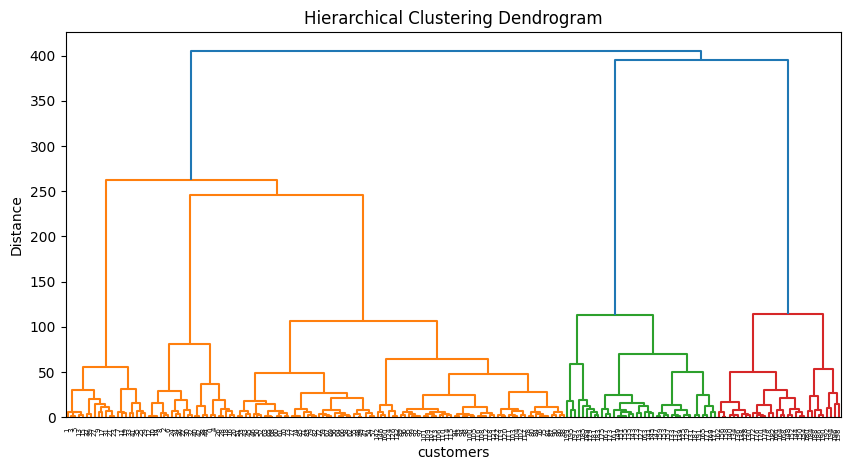

In [9]:
from matplotlib import figure
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
Z = linkage(X, method="ward")
plt.figure(figsize=(10, 5))
dendrogram(Z)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("customers")
plt.ylabel("Distance")
plt.show()

In [10]:
model = AgglomerativeClustering(n_clusters=5, linkage="ward")
df["cluster"] = model.fit_predict(X)

In [14]:
# Re-predict the clusters to add the column back to the current DataFrame
df["cluster"] = model.fit_predict(X)

# Print the results
print(df[["Annual Income (k$)", "Spending Score (1-100)", "cluster"]])

     Annual Income (k$)  Spending Score (1-100)  cluster
0                    15                      39        4
1                    15                      81        3
2                    16                       6        4
3                    16                      77        3
4                    17                      40        4
..                  ...                     ...      ...
195                 120                      79        2
196                 126                      28        0
197                 126                      74        2
198                 137                      18        0
199                 137                      83        2

[200 rows x 3 columns]


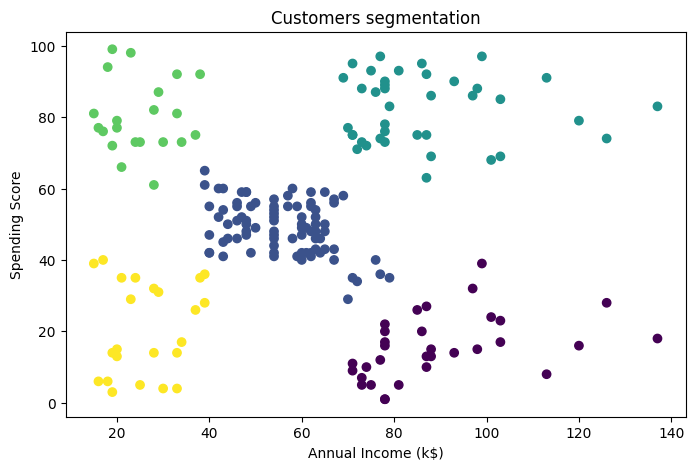

In [15]:
plt.figure(figsize=(8, 5))
plt.scatter(df["Annual Income (k$)"], df["Spending Score (1-100)"], c=df["cluster"])
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score")
plt.title("Customers segmentation")
plt.show()